# Upload Dataset to Google Colab

In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


**Extract Dataset from ZIP**

In [2]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Dataset location:", extract_path)
print("Folders:", os.listdir(extract_path))

Dataset extracted successfully!
Dataset location: /content/dataset
Folders: ['images']


**Verify Dataset Folder Structure**

In [3]:
import os

dataset_path = "/content/dataset/images"

print("Main folders:", os.listdir(dataset_path))

print("\nTraining classes:")
print(os.listdir(os.path.join(dataset_path, "train")))

print("\nValidation classes:")
print(os.listdir(os.path.join(dataset_path, "validation")))

Main folders: ['validation', 'images', 'train']

Training classes:
['angry', 'happy', 'sad', 'neutral', 'surprise', 'disgust', 'fear']

Validation classes:
['angry', 'happy', 'sad', 'neutral', 'surprise', 'disgust', 'fear']


# Importing Libraries

In [4]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os

# Deep Learning libraries
from tensorflow.keras.preprocessing.image import (
    load_img,
    img_to_array,
    ImageDataGenerator
)

from tensorflow.keras.layers import (
    Dense, Input, Dropout, GlobalAveragePooling2D,
    Flatten, Conv2D, BatchNormalization,
    Activation, MaxPooling2D
)

from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)

print("All libraries imported successfully!")


All libraries imported successfully!


# Displaying Images

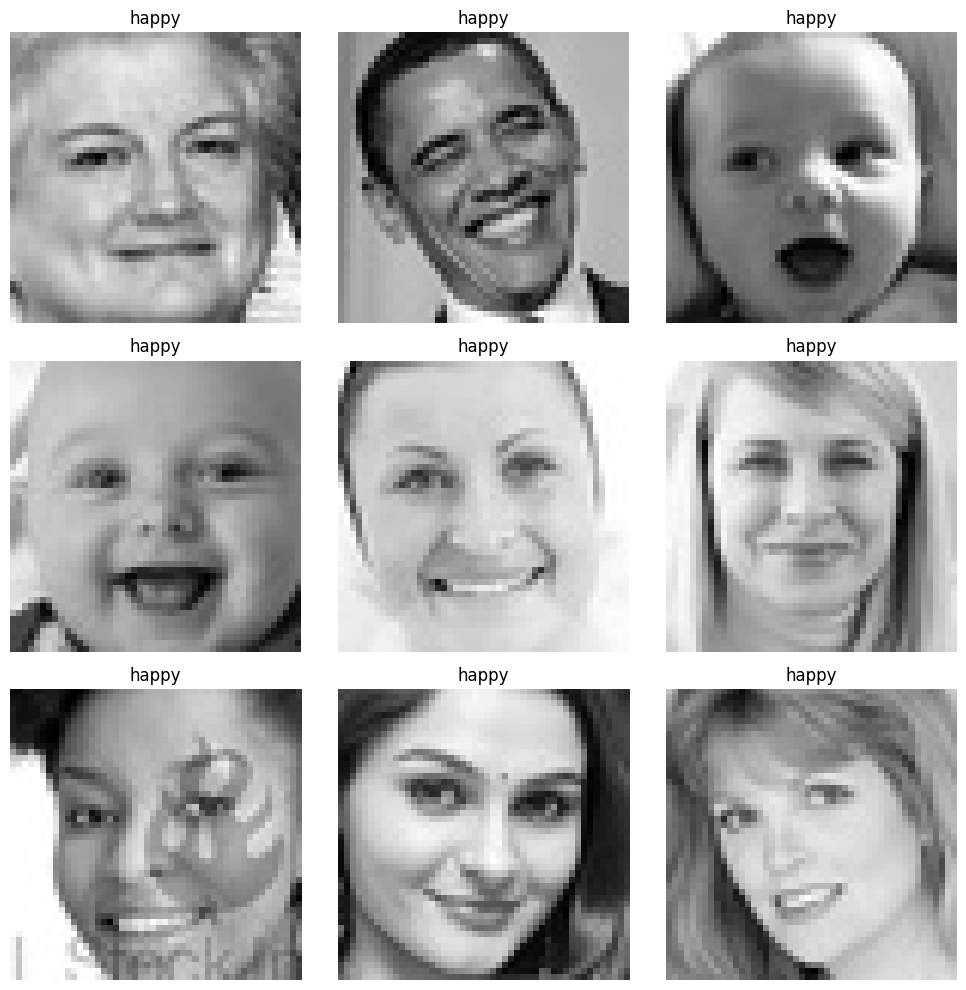

In [5]:
picture_size = 48
folder_path = "/content/dataset/images"

expression = "happy"

image_dir = os.path.join(folder_path, "train", expression)
image_files = sorted(os.listdir(image_dir))

plt.figure(figsize=(10, 10))

for i, filename in enumerate(image_files[:9], start=1):
    img_path = os.path.join(image_dir, filename)

    img = load_img(
        img_path,
        target_size=(picture_size, picture_size),
        color_mode="grayscale"
    )

    plt.subplot(3, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title(expression)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Making Training and Validation Data

In [7]:

batch_size = 128

datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen_val = ImageDataGenerator(
    rescale=1./255
)

train_set = datagen_train.flow_from_directory(
    os.path.join(folder_path, "train"),
    target_size=(picture_size, picture_size),
    color_mode="grayscale",
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=True
)

test_set = datagen_val.flow_from_directory(
    os.path.join(folder_path, "validation"),
    target_size=(picture_size, picture_size),
    color_mode="grayscale",
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

print("Class mapping:", train_set.class_indices)


Found 28821 images belonging to 7 classes.
Found 7066 images belonging to 7 classes.
Class mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


In [9]:
import numpy as np

class_counts = np.bincount(train_set.classes)

print("Training Dataset Class Distribution:\n")

for emotion, index in train_set.class_indices.items():
    print(f"{emotion.capitalize():10s}: {class_counts[index]} images")

print("\nTotal:", sum(class_counts))

Training Dataset Class Distribution:

Angry     : 3993 images
Disgust   : 436 images
Fear      : 4103 images
Happy     : 7164 images
Neutral   : 4982 images
Sad       : 4938 images
Surprise  : 3205 images

Total: 28821


**Calculate Class Weights for Imbalanced Dataset**

In [10]:
import numpy as np

class_counts = np.bincount(train_set.classes)

# Calculate moderate class weights
class_weights_array = np.sqrt(
    len(train_set.classes) /
    (len(class_counts) * class_counts)
)

# Normalize weights to have an average of 1
class_weights_array /= np.mean(class_weights_array)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("Class weights:")
for emotion, index in train_set.class_indices.items():
    print(emotion, ":", round(class_weights[index], 3))

Class weights:
angry : 0.807
disgust : 2.443
fear : 0.796
happy : 0.603
neutral : 0.723
sad : 0.726
surprise : 0.901


# Model Building

In [11]:
from keras.optimizers import Adam,SGD,RMSprop


no_of_classes = 7

model = Sequential()

#1st CNN layer
model.add(Conv2D(64,(3,3),padding = 'same',input_shape = (48,48,1)))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size = (2,2)))
model.add(Dropout(0.25))

#2nd CNN layer
model.add(Conv2D(128,(5,5),padding = 'same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size = (2,2)))
model.add(Dropout (0.25))

#3rd CNN layer
model.add(Conv2D(512,(3,3),padding = 'same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size = (2,2)))
model.add(Dropout (0.25))

#4th CNN layer
model.add(Conv2D(512,(3,3), padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())

#Fully connected 1st layer
model.add(Dense(256))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Dropout(0.25))


# Fully connected layer 2nd layer
model.add(Dense(512))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Dropout(0.25))

model.add(Dense(no_of_classes, activation='softmax'))



opt = Adam(learning_rate=0.0001)

model.compile(
    optimizer=opt,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 512)    │       590,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 6, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,02

 Total params: 4,478,727 (17.08 MB)

 Trainable params: 4,474,759 (17.07 MB)

 Non-trainable params: 3,968 (15.50 KB)

# Fitting the Model with Training and Validation Data

In [13]:

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

checkpoint = ModelCheckpoint(
    "./best_emotion_model.keras",
    monitor="val_accuracy",
    verbose=1,
    save_best_only=True,
    mode="max"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    verbose=1,
    restore_best_weights=True
)

reduce_learningrate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    verbose=1,
    min_delta=0.0001,
    min_lr=0.000001
)

callbacks_list = [
    checkpoint,
    early_stopping,
    reduce_learningrate
]

epochs = 50

model.compile(
    loss="categorical_crossentropy",
    optimizer=Adam(learning_rate=0.0001),
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


In [14]:
history = model.fit(
    train_set,
    epochs=epochs,
    validation_data=test_set,
    callbacks=callbacks_list,
    class_weight=class_weights
)


Epoch 1/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.1888 - loss: 1.6867
Epoch 1: val_accuracy improved from None to 0.17209, saving model to ./best_emotion_model.keras

Epoch 1: finished saving model to ./best_emotion_model.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 83s 239ms/step - accuracy: 0.2071 - loss: 1.6191 - val_accuracy: 0.1721 - val_loss: 1.8729 - learning_rate: 1.0000e-04
Epoch 2/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.2271 - loss: 1.5447
Epoch 2: val_accuracy improved from 0.17209 to 0.24512, saving model to ./best_emotion_model.keras

Epoch 2: finished saving model to ./best_emotion_model.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - accuracy: 0.2321 - loss: 1.5323 - val_accuracy: 0.2451 - val_loss: 1.9087 - learning_rate: 1.0000e-04
Epoch 3/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.2499 - loss: 1.4790
Epoch 3: val_accuracy improved from 0.24512 to 0.26847, saving model to ./best_emotion_model.keras

Epoch 3: finished sav

# Plotting Accuracy & Loss

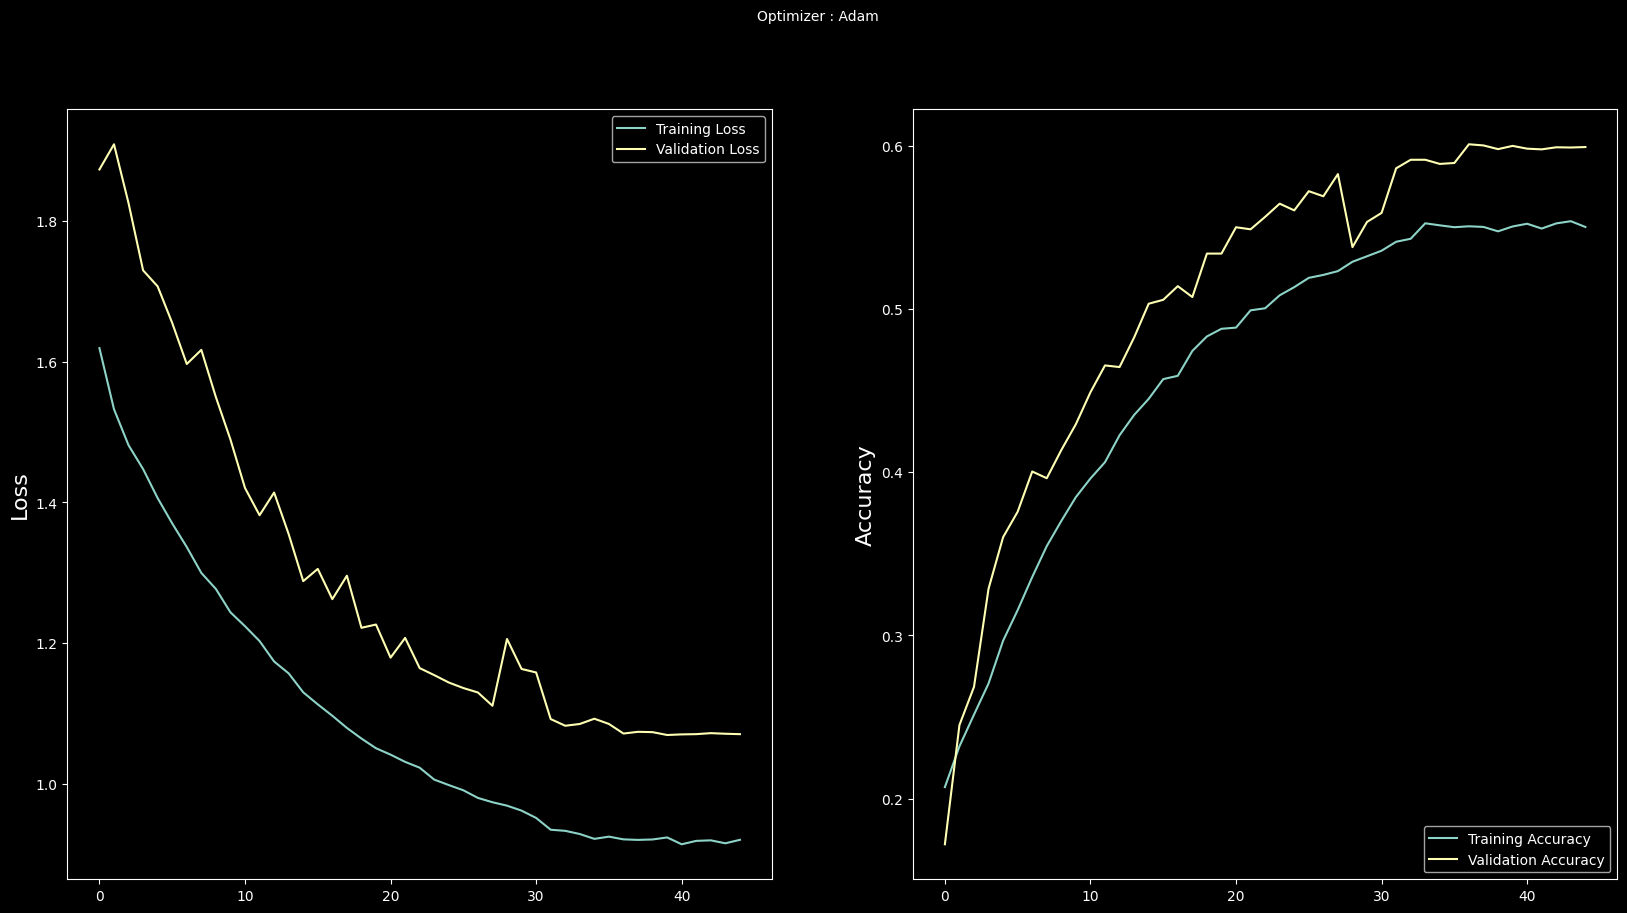

In [15]:
plt.style.use('dark_background')

plt.figure(figsize=(20,10))
plt.subplot(1, 2, 1)
plt.suptitle('Optimizer : Adam', fontsize=10)
plt.ylabel('Loss', fontsize=16)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend(loc='upper right')

plt.subplot(1, 2, 2)
plt.ylabel('Accuracy', fontsize=16)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend(loc='lower right')
plt.show()

**Evaluate Improved CNN Model**

56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.6008 - loss: 1.0715
Validation Loss: 1.0715391635894775
Validation Accuracy: 60.07642149925232 %
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step

Classification Report:

              precision    recall  f1-score   support

       angry       0.50      0.50      0.50       960
     disgust       0.33      0.68      0.45       111
        fear       0.56      0.22      0.32      1018
       happy       0.82      0.83      0.82      1825
     neutral       0.50      0.65      0.56      1216
         sad       0.49      0.46      0.47      1139
    surprise       0.64      0.81      0.72       797

    accuracy                           0.60      7066
   macro avg       0.55      0.59      0.55      7066
weighted avg       0.60      0.60      0.59      7066



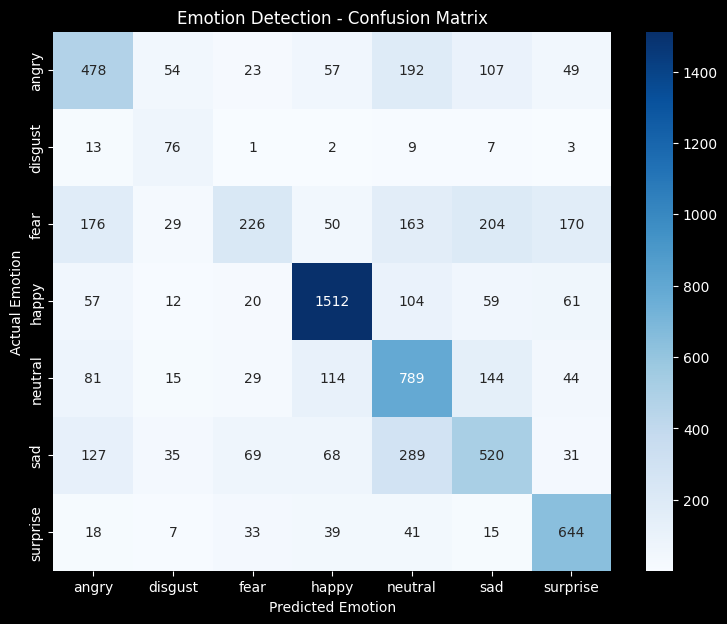

In [16]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix

# Load the best saved checkpoint
best_model = load_model("./best_emotion_model.keras")

# Evaluate on validation data
test_set.reset()

loss, accuracy = best_model.evaluate(test_set, verbose=1)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

# Generate predictions
test_set.reset()
predictions = best_model.predict(test_set, verbose=1)

y_pred = np.argmax(predictions, axis=1)
y_true = test_set.classes

# Get class names in correct order
class_names = [
    name for name, index in
    sorted(test_set.class_indices.items(), key=lambda x: x[1])
]

# Classification report
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Emotion Detection - Confusion Matrix")
plt.show()

**Save this trained model**

In [17]:
model.save("/content/retrained_baseline_model.keras")

print("Model saved successfully!")

Model saved successfully!


**Downloading the model**

In [18]:
from google.colab import files

files.download("/content/retrained_baseline_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Calculate new experimental class weights**

In [26]:
import numpy as np

class_counts = np.bincount(train_set.classes)

new_weights = np.sqrt(
    len(train_set.classes) / (len(class_counts) * class_counts)
)

# Give additional emphasis to difficult classes
new_weights[2] *= 1.5  # Fear
new_weights[5] *= 1.2  # Sad
new_weights[0] *= 1.1  # Angry

# Normalize weights
new_weights /= np.mean(new_weights)

new_class_weights = {
    i: float(weight)
    for i, weight in enumerate(new_weights)
}

for i, emotion in enumerate(train_set.class_indices.keys()):
    print(f"{emotion}: {new_class_weights[i]:.4f}")

angry: 0.8154
disgust: 2.2433
fear: 1.0969
happy: 0.5534
neutral: 0.6636
sad: 0.7999
surprise: 0.8274


**Save the current model as a safety backup**

In [27]:
retrained_model.save(
    "/content/retrained_baseline_backup.keras"
)

print("Baseline backup saved successfully!")

Baseline backup saved successfully!


**Create an experimental model copy**

In [29]:
import tensorflow as tf

experimental_model = tf.keras.models.clone_model(model)

experimental_model.set_weights(model.get_weights())

experimental_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Experimental model created successfully!")

Experimental model created successfully!


**Create new training callbacks**

In [30]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

experimental_callbacks = [
    ModelCheckpoint(
        "/content/best_targeted_emotion_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
]

print("Experimental callbacks configured successfully!")

Experimental callbacks configured successfully!


**Start experimental training**

In [31]:
history_experimental = experimental_model.fit(
    train_set,
    steps_per_epoch=len(train_set),
    epochs=50,
    validation_data=test_set,
    validation_steps=len(test_set),
    class_weight=new_class_weights,
    callbacks=experimental_callbacks
)

Epoch 1/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.5369 - loss: 0.9842
Epoch 1: val_accuracy improved from None to 0.58774, saving model to /content/best_targeted_emotion_model.keras

Epoch 1: finished saving model to /content/best_targeted_emotion_model.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 51s 167ms/step - accuracy: 0.5389 - loss: 0.9810 - val_accuracy: 0.5877 - val_loss: 1.0781 - learning_rate: 1.0000e-04
Epoch 2/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.5452 - loss: 0.9777
Epoch 2: val_accuracy did not improve from 0.58774
226/226 ━━━━━━━━━━━━━━━━━━━━ 28s 125ms/step - accuracy: 0.5411 - loss: 0.9803 - val_accuracy: 0.5609 - val_loss: 1.1515 - learning_rate: 1.0000e-04
Epoch 3/50
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.5483 - loss: 0.9658
Epoch 3: val_accuracy improved from 0.58774 to 0.60572, saving model to /content/best_targeted_emotion_model.keras

Epoch 3: finished saving model to /content/best_targeted_emotion_model.keras
226/22

**Load the best experimental checkpoint**

In [32]:
from tensorflow.keras.models import load_model

experimental_model = load_model(
    "/content/best_targeted_emotion_model.keras"
)

print("Best experimental model loaded!")

Best experimental model loaded!


**Evaluate experimental model**

In [33]:
test_set.reset()

exp_loss, exp_accuracy = experimental_model.evaluate(
    test_set,
    steps=len(test_set),
    verbose=1
)

print(f"Experimental Validation Loss: {exp_loss:.4f}")
print(f"Experimental Validation Accuracy: {exp_accuracy * 100:.2f}%")

56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.6196 - loss: 1.0202
Experimental Validation Loss: 1.0202
Experimental Validation Accuracy: 61.96%


**Generate the experimental classification report**

In [34]:
from sklearn.metrics import classification_report
import numpy as np

test_set.reset()

y_true_exp = test_set.classes

y_pred_prob_exp = experimental_model.predict(
    test_set,
    verbose=1
)

y_pred_exp = np.argmax(y_pred_prob_exp, axis=1)

print(classification_report(
    y_true_exp,
    y_pred_exp,
    target_names=list(test_set.class_indices.keys()),
    digits=4
))

56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step
              precision    recall  f1-score   support

       angry     0.5445    0.4781    0.5092       960
     disgust     0.3812    0.6216    0.4726       111
        fear     0.4746    0.3585    0.4085      1018
       happy     0.8382    0.8345    0.8364      1825
     neutral     0.5389    0.6439    0.5867      1216
         sad     0.4867    0.4987    0.4926      1139
    surprise     0.7309    0.7666    0.7483       797

    accuracy                         0.6196      7066
   macro avg     0.5707    0.6003    0.5792      7066
weighted avg     0.6185    0.6196    0.6163      7066



**Save the improved model**

In [35]:
experimental_model.save(
    "/content/emotion_model_v2_targeted.keras"
)

print("Improved model saved successfully!")

Improved model saved successfully!


**Download the improved model**

In [36]:
from google.colab import files

files.download("/content/emotion_model_v2_targeted.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>